# 02. Clasificación de entornos de Minecraft con una CNN

**Douglas Pérez**  
**Carnet 22003865**

## 1. Introducción y objetivo

Quise reconocer el entorno de Minecraft a partir de una captura. Elegí este dataset porque me permite comparar escenas con texturas y formas similares, como un bosque y una llanura. Usé siete clases de imágenes de 128 × 128: `caves`, `end`, `forests`, `nether`, `oceans`, `plains` y `sky`.

Los datos provienen de **Minecraft Vision Dataset**, publicado por Nininkkka con licencia CC BY-NC 4.0. [Dataset en Hugging Face](https://huggingface.co/datasets/Nininkkka/Minecraft-vision-dataset)

## 2. Carga y análisis exploratorio (EDA)

Fijé la revisión de Hugging Face y seleccioné las siete carpetas de 128 × 128. En la escala de 0 a 1, el brillo medio fue 0.680 en sky y 0.093 en caves. Como el brillo aporta información sobre el entorno, limité cuánto podía cambiar durante el data augmentation.

In [1]:
from pathlib import Path
import hashlib
import os
import random
import re
import shutil
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display

SEED = 42
CLASES = ["caves", "end", "forests", "nether", "oceans", "plains", "sky"]
REPOSITORIO = "https://huggingface.co/datasets/Nininkkka/Minecraft-vision-dataset"
REVISION = "a034526ff7944bffa4676a35775bf00356a9ee68"
RUTA_DATOS = Path(f"minecraft_vision_{REVISION[:8]}")
ESPERADAS = [1536, 1024, 2052, 1024, 1984, 2052, 2052]


def ejecutar(args, *, cwd=None, env=None):
    resultado = subprocess.run(args, cwd=cwd, env=env, text=True, capture_output=True)
    if resultado.returncode:
        raise RuntimeError(f"Falló {' '.join(args)}: {resultado.stderr or resultado.stdout}")
    return resultado.stdout.strip()


if shutil.which("git-lfs") is None:
    print("Instalando Git LFS en el runtime…", flush=True)
    ejecutar(["apt-get", "-qq", "update"])
    ejecutar(["apt-get", "-qq", "install", "-y", "git-lfs"])

RUTA_DATOS.mkdir(exist_ok=True)
if not (RUTA_DATOS / ".git").exists():
    ejecutar(["git", "init", "-q"], cwd=RUTA_DATOS)
    ejecutar(["git", "remote", "add", "origin", REPOSITORIO], cwd=RUTA_DATOS)

archivo_listo = RUTA_DATOS / ".descarga_completa"
if not archivo_listo.exists():
    print(f"Descargando {sum(ESPERADAS):,} capturas de Hugging Face…", flush=True)
    ejecutar(["git", "lfs", "install", "--local"], cwd=RUTA_DATOS)
    ejecutar(["git", "fetch", "--quiet", "--depth=1", "origin", REVISION], cwd=RUTA_DATOS)
    entorno_checkout = {**os.environ, "GIT_LFS_SKIP_SMUDGE": "1"}
    ejecutar(["git", "checkout", "--quiet", "--detach", "FETCH_HEAD"],
             cwd=RUTA_DATOS, env=entorno_checkout)
    # Las carpetas de mayor resolución y las etiquetas de hora quedan fuera.
    incluidos = ",".join(f"{clase}/**" for clase in CLASES)
    ejecutar(["git", "-c", "lfs.concurrenttransfers=24", "lfs", "pull",
              "--include", incluidos, "--exclude", ""], cwd=RUTA_DATOS)

rutas_clase = [sorted((RUTA_DATOS / clase).glob("*.jpg")) for clase in CLASES]
assert [len(rutas) for rutas in rutas_clase] == ESPERADAS
assert ejecutar(["git", "rev-parse", "HEAD"], cwd=RUTA_DATOS) == REVISION
for rutas in rutas_clase:
    with Image.open(rutas[0]) as primera:
        assert primera.size == (128, 128)
archivo_listo.touch()
print(f"{sum(map(len, rutas_clase)):,} capturas | {len(CLASES)} clases | revisión {REVISION[:8]}")

11,724 capturas | 7 clases | revisión a034526f


Imágenes legibles: 11,724 | Formato incorrecto o ilegibles: 0


,Capturas,Brillo medio,Desviación del brillo
clase,,,
caves,1536,0.093,0.058
end,1024,0.129,0.083
forests,2052,0.142,0.058
nether,1024,0.127,0.063
oceans,1984,0.222,0.142
plains,2052,0.227,0.112
sky,2052,0.680,0.077


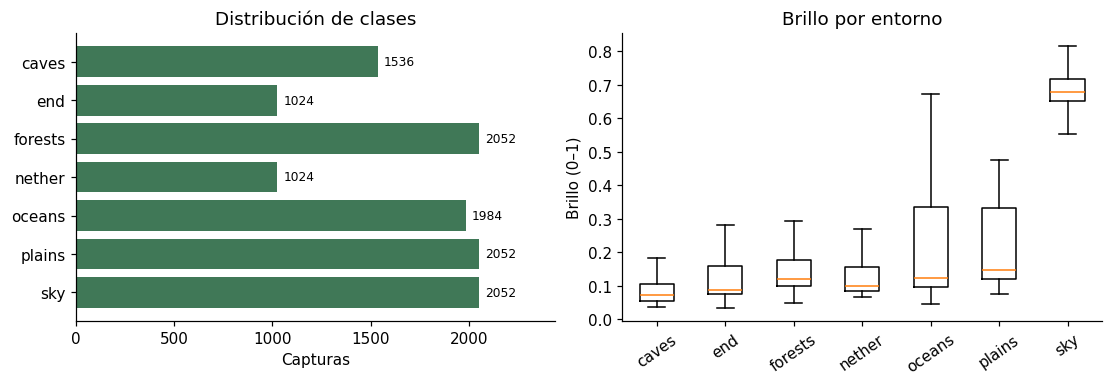

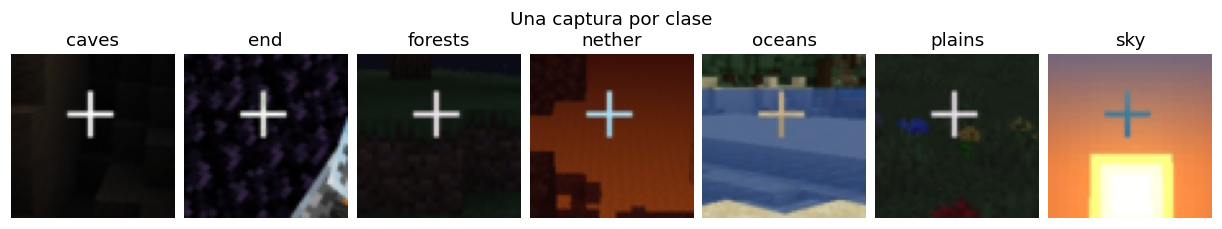

In [2]:
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
registros, capturas = [], []
invalidas = []

for etiqueta, rutas in enumerate(rutas_clase):
    for ruta in rutas:
        try:
            with Image.open(ruta) as archivo_imagen:
                rgb = archivo_imagen.convert("RGB")
                if rgb.size != (128, 128):
                    invalidas.append(f"{ruta.name}: {rgb.size}")
                    continue
                gris = rgb.convert("L")
                miniatura = np.asarray(gris.resize((9, 8), Image.Resampling.LANCZOS))
                firma = int.from_bytes(np.packbits(miniatura[:, 1:] > miniatura[:, :-1]).tobytes(), "big")
                registros.append({
                    "id": len(capturas), "clase": CLASES[etiqueta], "etiqueta": etiqueta,
                    "archivo": ruta.name, "sha256": hashlib.sha256(rgb.tobytes()).hexdigest(),
                    "dhash": firma, "brillo": np.asarray(gris).mean() / 255,
                })
                capturas.append(np.array(rgb.resize((64, 64), Image.Resampling.BILINEAR)))
        except OSError:
            invalidas.append(ruta.name)

imagenes = np.stack(capturas)
del capturas
datos = pd.DataFrame(registros)
assert len(datos) + len(invalidas) == sum(ESPERADAS)
print(f"Imágenes legibles: {len(datos):,} | Formato incorrecto o ilegibles: {len(invalidas)}")
if invalidas:
    print("Ejemplos descartados:", invalidas[:5])
conteos_clase = datos.groupby("clase")["brillo"].agg(["size", "mean", "std"]).reindex(CLASES)
display(conteos_clase.rename(columns={"size": "Capturas", "mean": "Brillo medio",
                                      "std": "Desviación del brillo"}).round(3))

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained")
barras = ejes[0].barh(CLASES, conteos_clase["size"], color="#407857")
ejes[0].bar_label(barras, padding=4, fontsize=8)
ejes[0].set(xlim=(0, conteos_clase["size"].max() * 1.19), xlabel="Capturas", title="Distribución de clases")
ejes[0].invert_yaxis()
ejes[1].boxplot([datos.loc[datos["clase"].eq(c), "brillo"] for c in CLASES], showfliers=False)
ejes[1].set(xticks=range(1, len(CLASES) + 1), xticklabels=CLASES,
            ylabel="Brillo (0–1)", title="Brillo por entorno")
ejes[1].tick_params(axis="x", rotation=35)
plt.show()

fig, ejes = plt.subplots(1, len(CLASES), figsize=(11, 2), layout="constrained")
for ax, clase in zip(ejes, CLASES):
    fila = datos[datos["clase"].eq(clase)].sample(random_state=SEED).iloc[0]
    ax.imshow(imagenes[fila["id"]])
    ax.set_title(clase)
    ax.axis("off")
fig.suptitle("Una captura por clase")
plt.show()

## 3. Preprocesamiento y split

Agrupé capturas con dHash a una distancia de Hamming de hasta 3. Mantuve cada grupo en un solo split, descarté grupos con etiquetas mezcladas y dejé una copia de cada captura idéntica. Usé siete folds estratificados por grupo: cinco para train, uno para validation y uno para test.

Redimensioné a 64 × 64 para entrenar en el runtime de Colab. Calculé la normalización con train y probé data augmentation únicamente en ese split, con reflejo horizontal, crop y cambios leves de brillo y contraste.

In [3]:
from collections import defaultdict
from sklearn.model_selection import StratifiedGroupKFold


def agrupar_dhash(firmas):
    padres = list(range(len(firmas)))
    bandas = defaultdict(list)
    vistos = {}

    def raiz(i):
        while padres[i] != i:
            padres[i] = padres[padres[i]]
            i = padres[i]
        return i

    def unir(i, j):
        ri, rj = raiz(i), raiz(j)
        padres[max(ri, rj)] = min(ri, rj)

    for i, firma in enumerate(map(int, firmas)):
        if firma in vistos:
            unir(i, vistos[firma])
            continue
        # Con hasta tres bits distintos, al menos una de las cuatro bandas coincide.
        llaves = [(banda, (firma >> (banda * 16)) & 0xFFFF) for banda in range(4)]
        candidatos = {otra for llave in llaves for otra in bandas[llave]}
        for otra in candidatos:
            if (firma ^ otra).bit_count() <= 3:
                unir(i, vistos[otra])
        for llave in llaves:
            bandas[llave].append(firma)
        vistos[firma] = i

    return np.array([raiz(i) for i in range(len(firmas))])


assert agrupar_dhash([0, 7, 31, (1 << 64) - 1]).tolist() == [0, 0, 0, 3]
datos["grupo"] = agrupar_dhash(datos["dhash"])
clases_por_grupo = datos.groupby("grupo")["clase"].nunique()
mezclados = clases_por_grupo.index[clases_por_grupo.gt(1)]
limpios = datos.loc[~datos["grupo"].isin(mezclados)].copy()
filas_mezcladas = len(datos) - len(limpios)
filas_identicas = int(limpios["sha256"].duplicated().sum())
limpios = limpios.drop_duplicates("sha256").reset_index(drop=True)

splitter = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
fold_id = np.full(len(limpios), -1)
for fold, (_, indices) in enumerate(splitter.split(limpios, limpios["etiqueta"], limpios["grupo"])):
    fold_id[indices] = fold
assert (fold_id >= 0).all()
limpios["split"] = np.select([fold_id == 0, fold_id == 1], ["test", "validation"], default="train")
assert limpios.groupby("grupo")["split"].nunique().eq(1).all()
orden_splits = ["train", "validation", "test"]
resumen_split = (pd.crosstab(limpios["clase"], limpios["split"])
                  .reindex(index=CLASES, columns=orden_splits, fill_value=0))
assert (resumen_split > 0).all().all()
print(f"Capturas retiradas por etiquetas mezcladas: {filas_mezcladas:,}")
print(f"Duplicados exactos retirados: {filas_identicas:,}")
print(f"Capturas finales: {len(limpios):,} | Grupos: {limpios['grupo'].nunique():,}")
print("Grupos compartidos entre splits: 0")
resumen_split.loc["Total"] = resumen_split.sum()
display(resumen_split)

Capturas retiradas por etiquetas mezcladas: 853
Duplicados exactos retirados: 4
Capturas finales: 10,867 | Grupos: 9,786
Grupos compartidos entre splits: 0


split,train,validation,test
clase,,,
caves,1019,209,178
end,572,117,97
forests,1479,312,251
nether,701,145,125
oceans,1138,236,207
plains,1488,306,255
sky,1275,572,185
Total,7672,1897,1298


PyTorch 2.14.1+cpu | Device: cpu | Seed: 42
Media RGB en train: [0.246 0.261 0.277] | Std: [0.226 0.25  0.317]


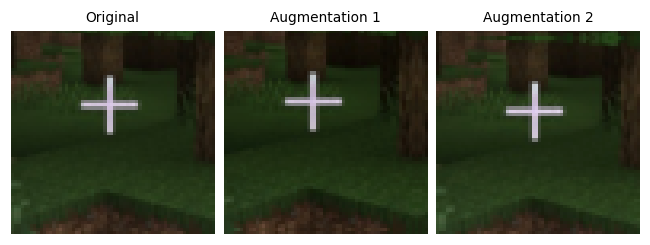

In [4]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | Device: {DEVICE} | Seed: {SEED}")

ids_train = limpios.loc[limpios["split"].eq("train"), "id"].to_numpy()
sumas = np.zeros(3)
sumas_cuadradas = np.zeros(3)
for bloque in np.array_split(ids_train, max(1, len(ids_train) // 256)):
    pixeles = imagenes[bloque].astype(np.float32) / 255
    sumas += pixeles.sum(axis=(0, 1, 2), dtype=np.float64)
    sumas_cuadradas += (pixeles ** 2).sum(axis=(0, 1, 2), dtype=np.float64)
n_pixeles = len(ids_train) * 64 * 64
media_rgb = sumas / n_pixeles
std_rgb = np.sqrt(sumas_cuadradas / n_pixeles - media_rgb ** 2)
assert (std_rgb > 0).all()
print("Media RGB en train:", np.round(media_rgb, 3), "| Std:", np.round(std_rgb, 3))

normalizar = v2.Compose([v2.ToDtype(torch.float32, scale=True), v2.Normalize(media_rgb.tolist(), std_rgb.tolist())])
augmentador = v2.Compose([
    v2.RandomHorizontalFlip(),
    v2.RandomCrop((64, 64), padding=4, padding_mode="reflect"),
    v2.ColorJitter(brightness=0.12, contrast=0.12),
])


class CapturasMinecraft(Dataset):
    def __init__(self, split, augmentation=False):
        filas = limpios.loc[limpios["split"].eq(split)]
        self.ids = filas["id"].to_numpy()
        self.labels = filas["etiqueta"].to_numpy()
        self.augmentation = augmentation

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):
        imagen = torch.from_numpy(imagenes[self.ids[index]]).permute(2, 0, 1)
        if self.augmentation:
            imagen = augmentador(imagen)
        return normalizar(imagen), int(self.labels[index])


fila = limpios.loc[limpios["split"].eq("train") & limpios["clase"].eq("forests")].iloc[0]
ejemplo = torch.from_numpy(imagenes[fila["id"]]).permute(2, 0, 1)
fig, ejes = plt.subplots(1, 3, figsize=(5.8, 2.2), layout="constrained")
for ax, imagen, titulo in zip(ejes, [ejemplo, augmentador(ejemplo), augmentador(ejemplo)],
                             ["Original", "Augmentation 1", "Augmentation 2"]):
    ax.imshow(imagen.permute(1, 2, 0))
    ax.set_title(titulo, fontsize=9)
    ax.axis("off")
plt.show()

## 4. Arquitectura de la CNN

Usé tres bloques convolucionales con batch normalization y ReLU. Reduje el tamaño espacial con stride 2 y conservé una cuadrícula de 2 × 2 antes de la capa final para que el modelo pueda distinguir, por ejemplo, cielo arriba y vegetación abajo. Comparé la misma arquitectura con y sin data augmentation.

In [5]:
def crear_cnn():
    capas = []
    for entrada, salida in [(3, 24), (24, 48), (48, 96)]:
        capas.extend([
            nn.Conv2d(entrada, salida, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(salida),
            nn.ReLU(),
        ])
    return nn.Sequential(
        *capas,
        nn.AdaptiveAvgPool2d((2, 2)),
        nn.Flatten(),
        nn.Dropout(0.20),
        nn.Linear(96 * 2 * 2, len(CLASES)),
    )


cnn = crear_cnn()
print(cnn)
print(f"Parámetros entrenables: {sum(p.numel() for p in cnn.parameters() if p.requires_grad):,}")
with torch.inference_mode():
    salida = cnn.eval()(torch.zeros(1, 3, 64, 64))
assert salida.shape == (1, len(CLASES))
print(f"Input: 3 × 64 × 64 | Output: {salida.shape[1]} logits")

Sequential(
  (0): Conv2d(3, 24, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (1): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): Conv2d(24, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (4): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (5): ReLU()
  (6): Conv2d(48, 96, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (7): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (8): ReLU()
  (9): AdaptiveAvgPool2d(output_size=(2, 2))
  (10): Flatten(start_dim=1, end_dim=-1)
  (11): Dropout(p=0.2, inplace=False)
  (12): Linear(in_features=384, out_features=7, bias=True)
)
Parámetros entrenables: 55,519
Input: 3 × 64 × 64 | Output: 7 logits


## 5. Training y selección del checkpoint

Entrené las dos variantes con CrossEntropyLoss y AdamW. Usé learning rate de 0.001, batch size de 128, un máximo de 8 epochs y early stopping de 3 epochs. Elegí el checkpoint con mayor macro F1-score en validation y usé validation loss para desempatar. Así cada clase tuvo el mismo peso en la selección.

In [6]:
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, precision_recall_fscore_support)

LEARNING_RATE = 0.001
BATCH_SIZE = 128
MAX_EPOCHS = 8
PATIENCE = 3
CARPETA_CHECKPOINTS = Path("checkpoints_cnn")
CARPETA_CHECKPOINTS.mkdir(exist_ok=True)
LABEL_IDS = np.arange(len(CLASES))
criterio = nn.CrossEntropyLoss()


def crear_loader(split, augmentation=False):
    if augmentation and split != "train":
        raise ValueError("El data augmentation está reservado para train.")
    return DataLoader(
        CapturasMinecraft(split, augmentation=augmentation),
        batch_size=BATCH_SIZE, shuffle=split == "train",
        generator=torch.Generator().manual_seed(SEED),
        pin_memory=DEVICE.type == "cuda",
    )


def pasar_epoch(modelo, loader, optimizer=None):
    training = optimizer is not None
    modelo.train(training)
    total_loss = 0.0
    etiquetas, logits_guardados = [], []
    for lotes, labels in loader:
        x = lotes.to(DEVICE, non_blocking=True)
        y = labels.to(DEVICE, non_blocking=True)
        with torch.set_grad_enabled(training):
            logits = modelo(x)
            loss = criterio(logits, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * len(labels)
        etiquetas.append(labels.numpy())
        logits_guardados.append(logits.detach().cpu().numpy())
    reales = np.concatenate(etiquetas)
    scores = np.concatenate(logits_guardados)
    predicciones = scores.argmax(axis=1)
    return {
        "loss": total_loss / len(reales),
        "accuracy": accuracy_score(reales, predicciones),
        "macro_f1": f1_score(reales, predicciones, labels=LABEL_IDS, average="macro", zero_division=0),
        "labels": reales,
        "logits": scores,
    }


def entrenar(usar_augmentation, ruta):
    torch.manual_seed(SEED)
    modelo = crear_cnn().to(DEVICE)
    optimizer = torch.optim.AdamW(modelo.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    train_loader = crear_loader("train", augmentation=usar_augmentation)
    valid_loader = crear_loader("validation")
    mejor = (-np.inf, -np.inf)
    best_epoch = 0
    historial = []
    for epoch in range(1, MAX_EPOCHS + 1):
        train = pasar_epoch(modelo, train_loader, optimizer)
        valid = pasar_epoch(modelo, valid_loader)
        historial.append({
            "Epoch": epoch, "Train loss": train["loss"], "Validation loss": valid["loss"],
            "Train accuracy": train["accuracy"], "Validation accuracy": valid["accuracy"],
            "Validation macro F1": valid["macro_f1"],
        })
        score = (valid["macro_f1"], -valid["loss"])
        if score > mejor:
            mejor, best_epoch = score, epoch
            torch.save(modelo.state_dict(), ruta)
        print(f"Epoch {epoch:02d} | train loss {train['loss']:.4f} | "
              f"validation loss {valid['loss']:.4f} | macro F1 {valid['macro_f1']:.4f}", flush=True)
        if epoch - best_epoch >= PATIENCE:
            break
    assert ruta.is_file()
    return pd.DataFrame(historial), best_epoch

In [7]:
variantes = {"CNN base": False, "CNN con augmentation": True}
historiales, rutas_checkpoint = {}, {}
filas_validacion = []
for i, (nombre, usar_augmentation) in enumerate(variantes.items(), start=1):
    print(f"\n{nombre}", flush=True)
    ruta = CARPETA_CHECKPOINTS / f"cnn_{i}_mejor.pt"
    historial, best_epoch = entrenar(usar_augmentation, ruta)
    historiales[nombre] = historial
    rutas_checkpoint[nombre] = ruta
    mejor = historial.loc[historial["Epoch"].eq(best_epoch)].iloc[0]
    filas_validacion.append({"Modelo": nombre, "Best epoch": best_epoch,
                             "Validation macro F1": mejor["Validation macro F1"],
                             "Validation accuracy": mejor["Validation accuracy"],
                             "Validation loss": mejor["Validation loss"]})

tabla_validacion = (pd.DataFrame(filas_validacion)
                   .sort_values(["Validation macro F1", "Validation loss"], ascending=[False, True]))
seleccion = tabla_validacion.iloc[0]
modelo_elegido = crear_cnn().to(DEVICE)
modelo_elegido.load_state_dict(torch.load(rutas_checkpoint[seleccion["Modelo"]],
                                         map_location=DEVICE, weights_only=True))
display(tabla_validacion.round(4))
print(f"Checkpoint seleccionado: {seleccion['Modelo']} | epoch {int(seleccion['Best epoch'])}")


CNN base
Epoch 01 | train loss 0.6532 | validation loss 0.2928 | macro F1 0.8815
Epoch 02 | train loss 0.2022 | validation loss 0.0812 | macro F1 0.9815
Epoch 03 | train loss 0.1170 | validation loss 0.0543 | macro F1 0.9860
Epoch 04 | train loss 0.1080 | validation loss 0.0880 | macro F1 0.9704
Epoch 05 | train loss 0.0666 | validation loss 0.0835 | macro F1 0.9740
Epoch 06 | train loss 0.0818 | validation loss 0.0364 | macro F1 0.9857

CNN con augmentation
Epoch 01 | train loss 0.6739 | validation loss 0.2489 | macro F1 0.9406
Epoch 02 | train loss 0.2204 | validation loss 0.0859 | macro F1 0.9819
Epoch 03 | train loss 0.1378 | validation loss 0.0558 | macro F1 0.9899
Epoch 04 | train loss 0.1282 | validation loss 0.0770 | macro F1 0.9811
Epoch 05 | train loss 0.0849 | validation loss 0.0276 | macro F1 0.9931
Epoch 06 | train loss 0.0947 | validation loss 0.0546 | macro F1 0.9810
Epoch 07 | train loss 0.0706 | validation loss 0.0293 | macro F1 0.9934
Epoch 08 | train loss 0.0675 | v

,Modelo,Best epoch,Validation macro F1,Validation accuracy,Validation loss
1,CNN con augmentation,7,0.9934,0.9947,0.0293
0,CNN base,3,0.9860,0.9900,0.0543


Checkpoint seleccionado: CNN con augmentation | epoch 7


## 6. Evaluación en test

Comparé las curvas de train y validation en ambas variantes. El modelo elegido usa el checkpoint de validation. En test reporté accuracy, macro precision, macro recall y macro F1-score, y revisé qué entornos se confunden entre sí.

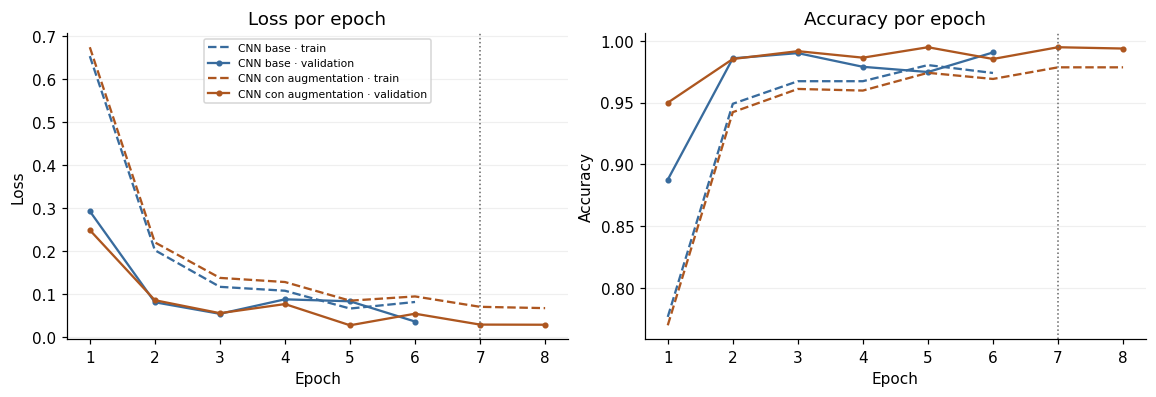

In [8]:
colores = ["#386b9d", "#ad561f"]
fig, ejes = plt.subplots(1, 2, figsize=(10.4, 3.5), layout="constrained")
for color, (nombre, tabla) in zip(colores, historiales.items()):
    for ax, metrica in zip(ejes, ["loss", "accuracy"]):
        ax.plot(tabla["Epoch"], tabla[f"Train {metrica}"], "--", color=color,
                label=f"{nombre} · train")
        ax.plot(tabla["Epoch"], tabla[f"Validation {metrica}"], color=color, marker=".",
                label=f"{nombre} · validation")
        ax.set(xlabel="Epoch", ylabel=metrica.capitalize())
        ax.grid(axis="y", alpha=0.20)
for ax in ejes:
    ax.axvline(seleccion["Best epoch"], linestyle=":", color="#666666", linewidth=1)
ejes[0].set_title("Loss por epoch")
ejes[1].set_title("Accuracy por epoch")
ejes[0].legend(fontsize=7)
plt.show()

,Test
Loss,0.0549
Accuracy,0.9861
Macro precision,0.9861
Macro recall,0.9835
Macro F1-score,0.9847


,precision,recall,f1-score,support
caves,0.9568,0.9944,0.9752,178.0
end,0.9787,0.9485,0.9634,97.0
forests,0.9879,0.9761,0.9820,251.0
nether,1.0000,0.9840,0.9919,125.0
oceans,1.0000,0.9855,0.9927,207.0
plains,0.9845,0.9961,0.9903,255.0
sky,0.9946,1.0000,0.9973,185.0


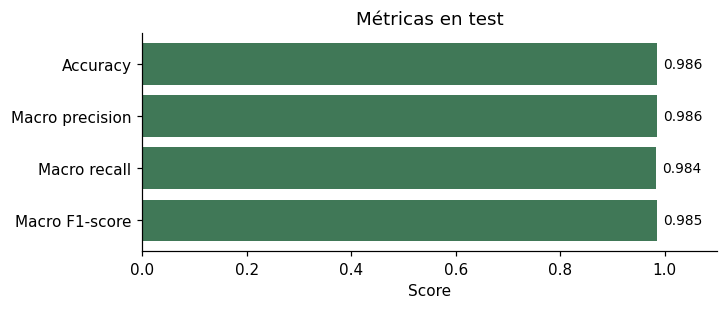

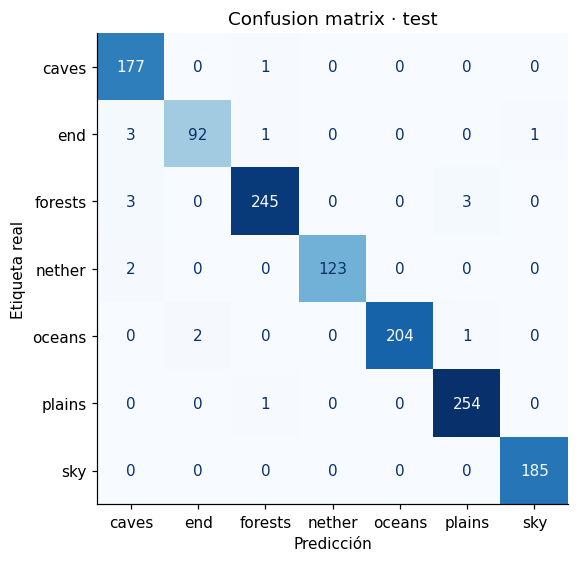

Confusiones más frecuentes (3 capturas cada una): end → caves, forests → caves, forests → plains


In [11]:
test_loader = crear_loader("test")
resultado_test = pasar_epoch(modelo_elegido, test_loader)
y_test = resultado_test["labels"]
probabilidades = torch.from_numpy(resultado_test["logits"]).softmax(dim=1).numpy()
y_pred = probabilidades.argmax(axis=1)
assert len(y_test) == resumen_split.loc["Total", "test"]
assert np.array_equal(y_test, limpios.loc[limpios["split"].eq("test"), "etiqueta"].to_numpy())

precision, recall, f1, _ = precision_recall_fscore_support(
    y_test, y_pred, labels=LABEL_IDS, average="macro", zero_division=0
)
metricas_test = pd.Series({"Loss": resultado_test["loss"], "Accuracy": resultado_test["accuracy"],
                           "Macro precision": precision, "Macro recall": recall, "Macro F1-score": f1})
display(metricas_test.to_frame("Test").round(4))
reporte = pd.DataFrame(classification_report(y_test, y_pred, labels=LABEL_IDS,
                       target_names=CLASES, output_dict=True, zero_division=0)).T.loc[CLASES]
display(reporte.round(4))

fig, ax = plt.subplots(figsize=(6.5, 2.7), layout="constrained")
barras = ax.barh(metricas_test.index[1:], metricas_test.iloc[1:], color="#407857")
ax.bar_label(barras, fmt="%.3f", padding=4, fontsize=9)
ax.set(xlim=(0, 1.10), xlabel="Score", title="Métricas en test")
ax.invert_yaxis()
plt.show()

matriz = confusion_matrix(y_test, y_pred, labels=LABEL_IDS)
assert matriz.sum() == len(y_test)
fig, ax = plt.subplots(figsize=(6.4, 5), layout="constrained")
ConfusionMatrixDisplay(matriz, display_labels=CLASES).plot(ax=ax, colorbar=False,
                                                          cmap="Blues", values_format="d")
ax.set(xlabel="Predicción", ylabel="Etiqueta real", title="Confusion matrix · test")
plt.show()

fuera_diagonal = matriz.copy()
np.fill_diagonal(fuera_diagonal, 0)
max_errores = int(fuera_diagonal.max())
if max_errores:
    pares = np.argwhere(fuera_diagonal == max_errores)
    confusiones = ", ".join(f"{CLASES[i]} → {CLASES[j]}" for i, j in pares)
    print(f"Confusiones más frecuentes ({max_errores} capturas cada una): {confusiones}")

### Ejemplos de predicciones

Elegí hasta cuatro aciertos y cuatro errores con mayor score para revisar qué escenas confundieron a la CNN aun cuando favoreció una clase con claridad.

,Real,Predicción,Score,Acierto
0,forests,forests,1.000,True
1,plains,plains,1.000,True
2,plains,plains,1.000,True
3,plains,plains,1.000,True
4,oceans,end,0.994,False
5,nether,caves,0.942,False
6,oceans,end,0.938,False
7,forests,plains,0.917,False


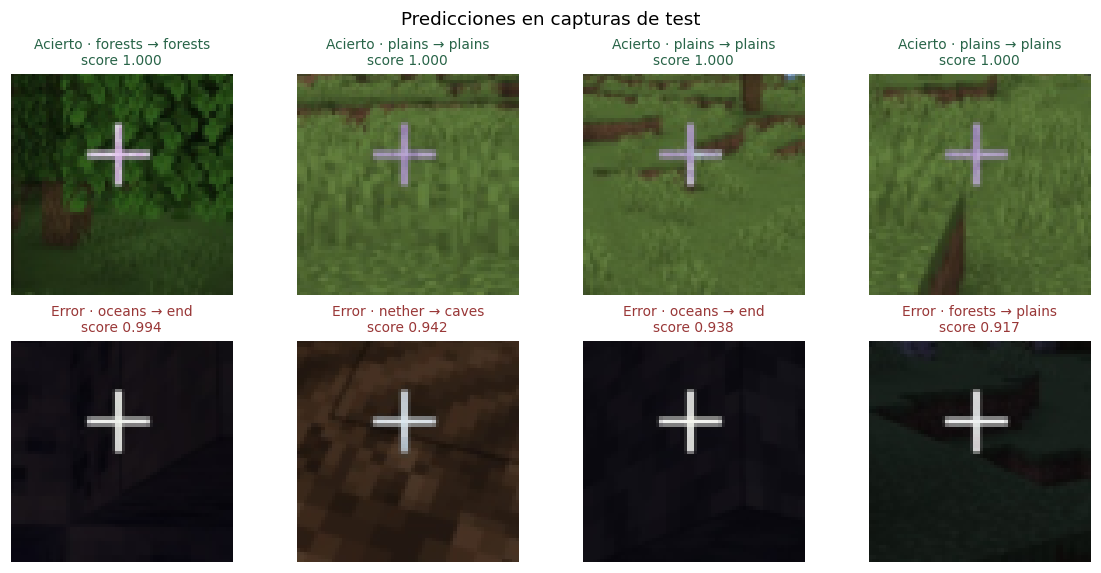

In [12]:
ids_test = test_loader.dataset.ids
resumen_ejemplos = pd.DataFrame({
    "id": ids_test, "Real": np.take(CLASES, y_test), "Predicción": np.take(CLASES, y_pred),
    "Score": probabilidades.max(axis=1), "Acierto": y_test == y_pred,
}).sort_values("Score", ascending=False)
casos = pd.concat([resumen_ejemplos[resumen_ejemplos["Acierto"]].head(4),
                   resumen_ejemplos[~resumen_ejemplos["Acierto"]].head(4)])
display(casos.drop(columns="id").round(3).reset_index(drop=True))

fig, ejes = plt.subplots(2, 4, figsize=(10.4, 5.1), layout="constrained")
for ax in ejes.flat:
    ax.axis("off")
for ax, fila in zip(ejes.flat, casos.itertuples(index=False)):
    ax.imshow(imagenes[fila.id])
    tipo = "Acierto" if fila.Acierto else "Error"
    ax.set_title(f"{tipo} · {fila.Real} → {fila.Predicción}\nscore {fila.Score:.3f}",
                 color="#286448" if fila.Acierto else "#993737", fontsize=9)
fig.suptitle("Predicciones en capturas de test")
plt.show()

## 7. Análisis y conclusiones

Elegí la CNN con augmentation en el epoch 7. En validation obtuvo 0.9934 de macro F1-score, frente a 0.9860 de la CNN base. Con ese checkpoint obtuve **98.61 % de accuracy**, **0.9847 de macro F1-score** y un **test loss de 0.0549** sobre 1,298 capturas.

Los errores que más se repitieron fueron end → caves, forests → caves y forests → plains, con tres capturas cada uno. El error con mayor score fue una captura oscura de oceans que la CNN clasificó como end con 0.994.

El split por dHash reduce la similitud entre particiones. La fuente identifica las capturas con nombres numerados y no indica qué mundo o sesión corresponde a cada una. En una siguiente prueba usaría capturas de otros mundos y paquetes de texturas para medir qué tan bien generaliza la CNN.